# 2. Baseline: TF-IDF with Multinomial Naive Bayes

We represent each article with TF-IDF weighted unigrams and bigrams (sublinear term frequency, minimum document frequency of 2) and classify it with Multinomial Naive Bayes. The additive smoothing parameter alpha is selected on the validation split. The selected configuration is then refit on the training and validation data and evaluated once on the official test split of 7,600 articles.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
from src import config
from src.preprocess import preprocess_and_save

if not (config.PROCESSED_DIR / "ag_news_clean_train.csv").exists():
    from src.download_data import download
    download()
    preprocess_and_save()

## 2.1 Model selection and training

In [3]:
from src.train_naive_bayes import main as train_naive_bayes

model, metrics = train_naive_bayes()

alpha=0.01  val_accuracy=0.9124


alpha=0.03  val_accuracy=0.9133


alpha=0.1   val_accuracy=0.9133


alpha=0.3   val_accuracy=0.9131


alpha=1.0   val_accuracy=0.9102
Selected alpha = 0.03


Test accuracy = 0.9079, macro-F1 = 0.9077


## 2.2 Test-set evaluation

In [4]:
import pandas as pd

report = pd.DataFrame(metrics["per_class"]).T.loc[config.LABEL_NAMES + ["macro avg"], ["precision", "recall", "f1-score", "support"]]
print(f"Accuracy: {metrics['accuracy']:.4f}   Macro-F1: {metrics['macro_f1']:.4f}")
report.round(4)

Accuracy: 0.9079   Macro-F1: 0.9077


,precision,recall,f1-score,support
World,0.9317,0.8900,0.9104,1900.0
Sports,0.9512,0.9842,0.9674,1900.0
Business,0.8783,0.8626,0.8704,1900.0
Sci/Tech,0.8705,0.8947,0.8824,1900.0
macro avg,0.9079,0.9079,0.9077,7600.0


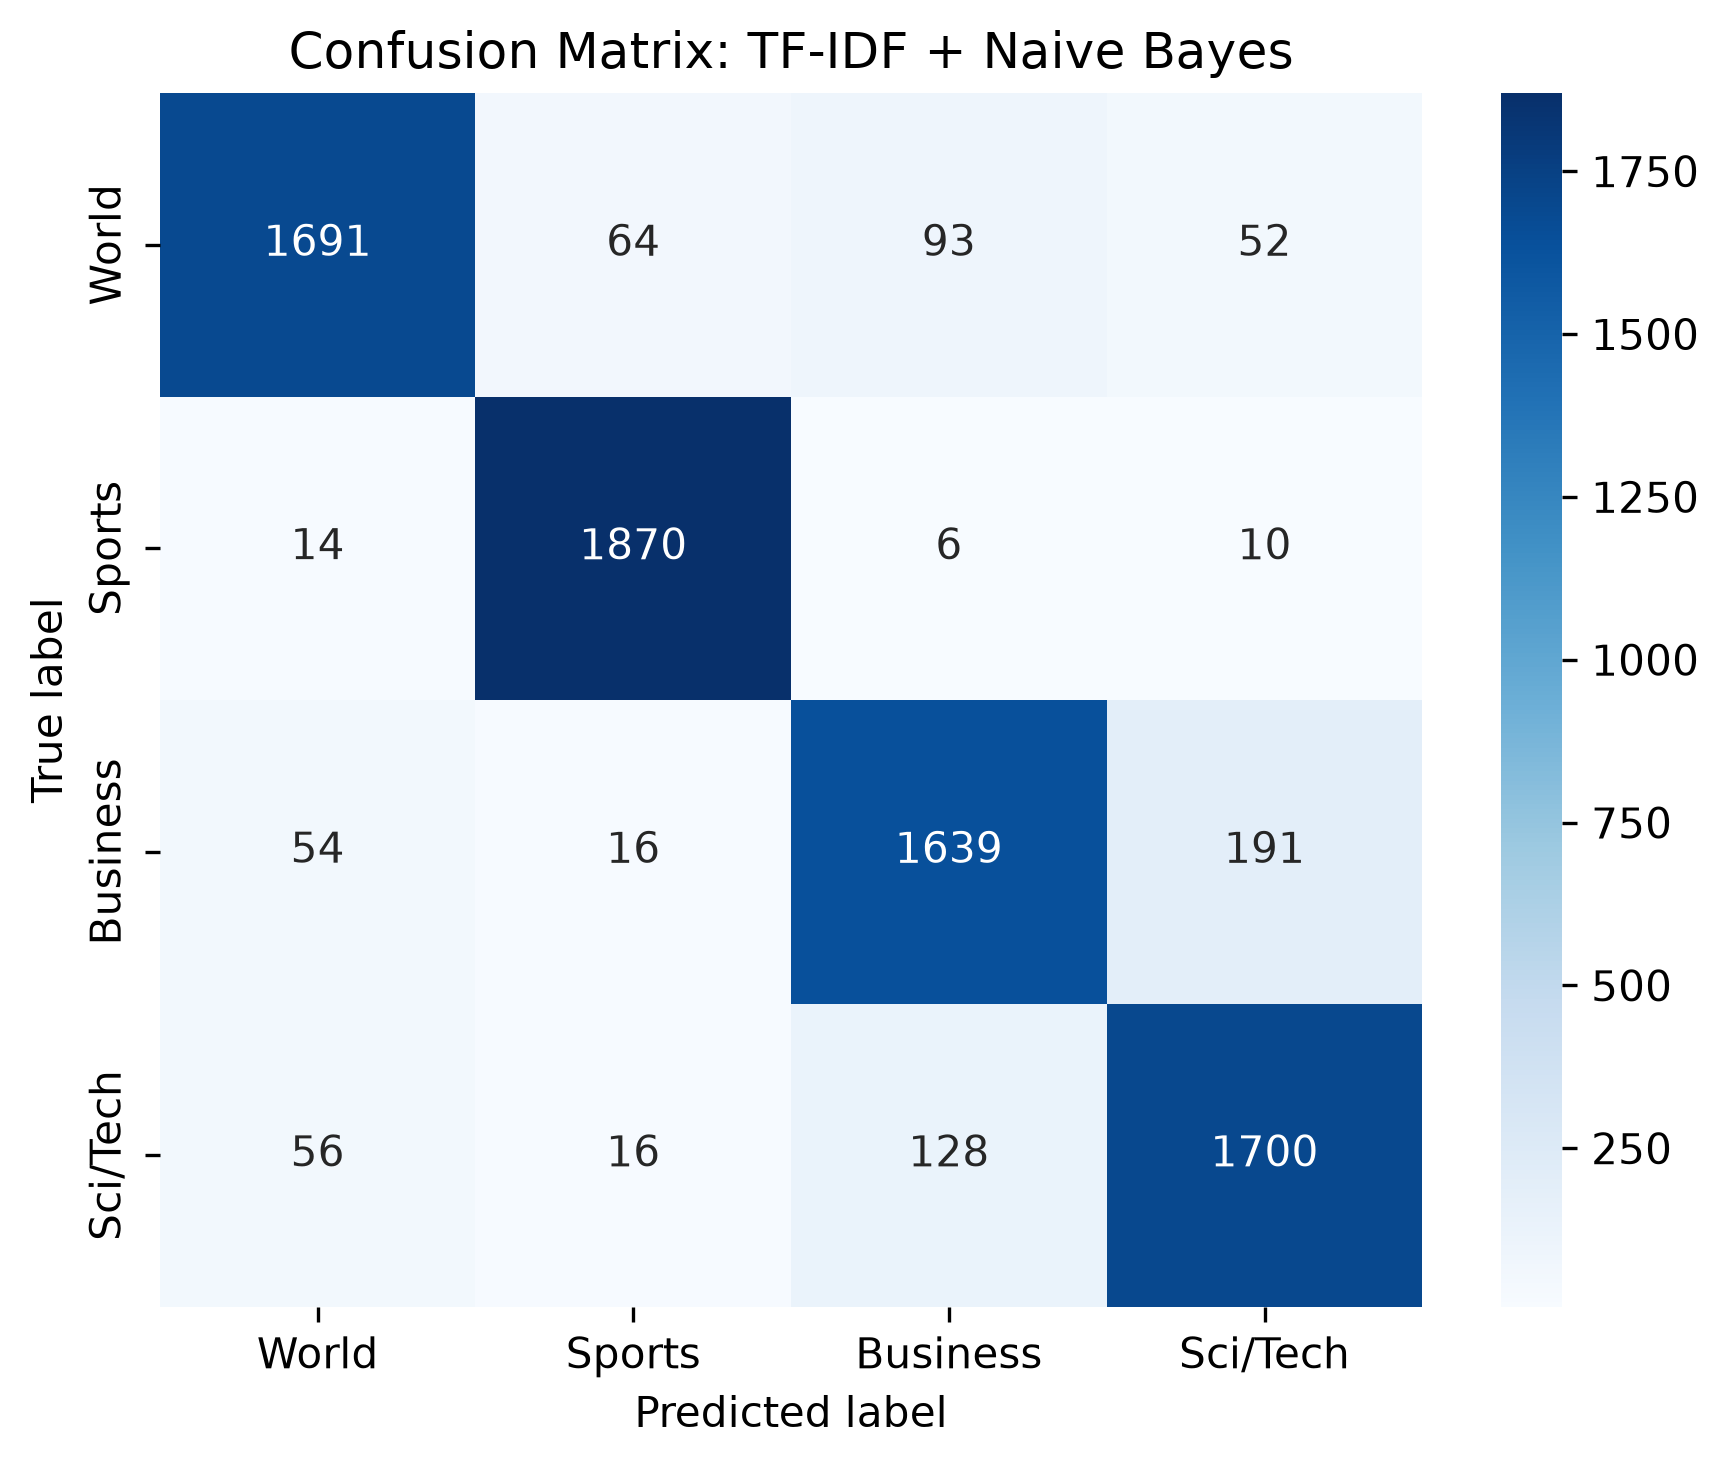

In [5]:
from IPython.display import Image, display

display(Image(filename=str(config.FIGURES_DIR / "nb_confusion_matrix.png"), width=480))

Most residual errors involve the Business and Sci/Tech classes, whose vocabularies overlap (technology companies, markets, earnings).

## 2.3 Explaining individual predictions with LIME

We apply LIME (Ribeiro et al., 2016) to individual test articles. LIME removes words at random, queries the classifier on 5,000 perturbed copies and fits a sparse linear surrogate whose weights indicate how much each word pushes the prediction towards (positive) or away from (negative) the predicted class.

Article: fears for t n pension after talks unions representing workers at turner newall say they are disappointed after talks with stricken parent firm federal mogul
True label: Business | predicted: Business (p = 0.998)
  mogul                +0.0626
  newall               +0.0584
  pension              +0.0570
  unions               +0.0404
  parent               +0.0354
  workers              +0.0341
  representing         +0.0333
  talks                -0.0255
  federal              +0.0252
  firm                 +0.0231


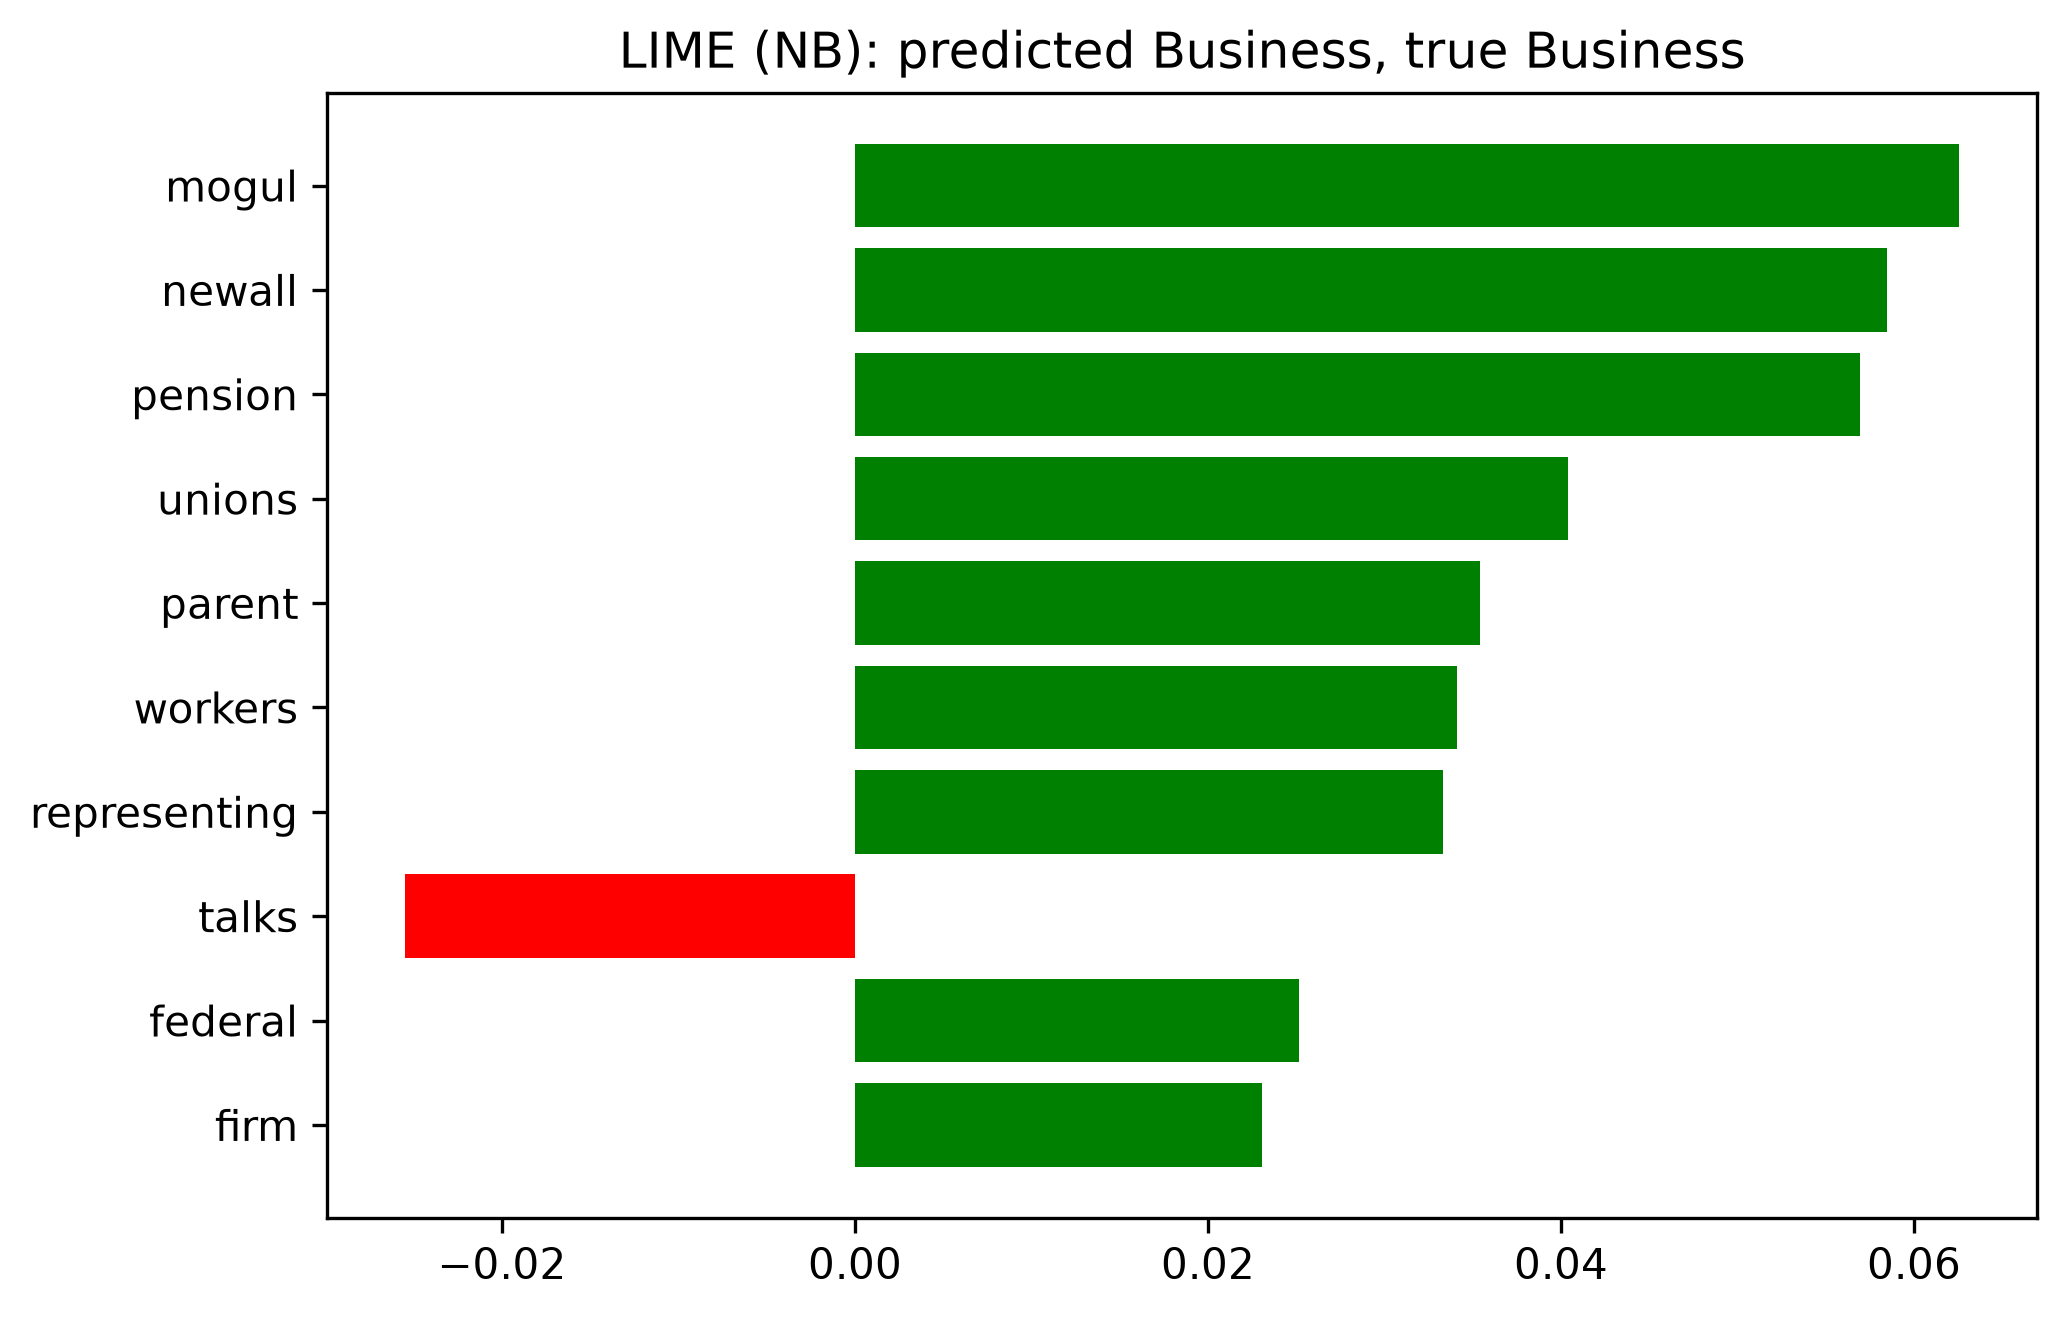

In [6]:
from src.explain_model import explain

exp = explain(model="nb", index=0)
display(Image(filename=str(config.FIGURES_DIR / "lime_nb_test0.png"), width=640))

In [7]:
from IPython.display import HTML

# Interactive view (rendered in Jupyter and Colab).
display(HTML(exp.as_html(labels=exp.top_labels)))